# TP1: Análisis exploratorio del inventario de una red GPON

**Aprendizaje Automático y Grandes Datos, UNRaf, 2026.** Juan Ignacio Forzani, Alejo Racca y Agustín Cesano.

**Pregunta.** ¿Dónde está el cuello de botella del servicio que reciben los clientes de la red?

**Datos.** El inventario de ONT (el módem de fibra de cada cliente) que entregó una empresa de telecomunicaciones de la
región: una fila por equipo, con su ubicación en la red (localidad, tarjeta, puerto PON e identificador), el modelo, la
versión de firmware y cinco atributos de hardware. Es una foto estática: no tiene fechas, estados ni fallas.

**Recorrido.** 1) Carga y limpieza · 2) Chequeos de calidad · 3) Variables derivadas · 4) Hallazgos (Wi-Fi, puertos,
localidades, modelos, firmware, ocupación) · 5) Relación entre variables · 6) Valores atípicos · 7) Fuga de datos ·
8) Indicador, meta SMART y plan de recambio · 9) Conclusiones.

In [1]:
# Configuración: rutas y librerías. El notebook se puede abrir desde notebooks/ o desde la raíz del proyecto.
import os, sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from IPython.display import display

import preparacion as prep          # mismas funciones que la Fase 1 (run_all.py)
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, GRIS, NARANJA = "#2a78d6", "#b8b5ad", "#d9733f"

## 1. Carga y limpieza

El archivo trae la hoja principal `DATOS_NORMALIZADOS` (una fila por ONT) y la tabla `EQUIVALENCIAS_CONSOLIDADO` con las
especificaciones de cada modelo. Dos problemas de origen que corregimos:

- **Nombres de localidad mal concatenados** (por ejemplo, «CastelarCrispi»): se reemplazan por nombres legibles.
- **Alias de modelo**: el mismo equipo aparece con dos nombres (por ejemplo, «546M» y «HG8546M»). Se consolidan en un
  nombre canónico, que es el que se usa en todo el análisis.

In [2]:
# Leemos el Excel (solo lectura) y miramos su forma y sus columnas.
df, eq = prep.cargar()
print(f"Inventario: {df.shape[0]} filas x {df.shape[1]} columnas")
display(df.head())
print("Valores faltantes por columna:", int(df.isna().sum().sum()))
print("Columnas constantes (no aportan):", [c for c in df.columns if df[c].nunique() == 1])

Inventario: 5114 filas x 13 columnas


,Localidad,Board,Slot,PON,ID,Marca,Modelo,Version,Puertos_LAN,WiFi_Tecnologia,Modulo_Optico,Puertos_POTS,CATV
0,San Vicente,0/,0/,0/,1,HWTC,CN1001,V5R019C00S050,1 GE + 3 FE,Wi-Fi 4 (2.4 GHz),GPON Class B+/C+,1,No
1,San Vicente,0/,0/,0/,4,HWTC,HG8546M,V3R017C10S125,1 GE + 3 FE,Wi-Fi 4 (2.4 GHz),GPON Class B+/C+,1,No
2,San Vicente,0/,0/,0/,9,HWTC,EG8141A5,V5R019C10S100,1 GE + 3 FE,Wi-Fi 4 (2.4 GHz),GPON Class B+/C+,1,No
3,San Vicente,0/,0/,1/,0,HWTC,CN1001,V5R019C00S050,1 GE + 3 FE,Wi-Fi 4 (2.4 GHz),GPON Class B+/C+,1,No
4,San Vicente,0/,0/,1/,1,HWTC,CN1001,V5R019C00S050,1 GE + 3 FE,Wi-Fi 4 (2.4 GHz),GPON Class B+/C+,1,No


Valores faltantes por columna: 0
Columnas constantes (no aportan): ['Board', 'Marca']


In [3]:
# Alias de modelo y nombres de localidad que se corrigen.
display(pd.DataFrame(prep.ALIAS_MODELO.items(), columns=["alias en el inventario", "nombre canónico"]))
display(pd.DataFrame(prep.NOMBRE_LOCALIDAD.items(), columns=["nombre original", "nombre corregido"]))
print("Modelos con nombre original:", df["Modelo"].nunique(), "→ equipos físicos:",
      df["Modelo"].replace(prep.ALIAS_MODELO).nunique())

,alias en el inventario,nombre canónico
0,546M,HG8546M
1,247H,HG8247H5
2,8247H5,HG8247H5
3,8546V,HS8546V
4,8545M,HS8545M
5,8245H5,HG8245H5


,nombre original,nombre corregido
0,Bernardo de IrigoyenIrigoyenSan,Bernardo de Irigoyen
1,CastelarCrispi,Castelar / Crispi


Modelos con nombre original: 24 → equipos físicos: 22


## 2. Variables derivadas

Sobre el inventario limpio agregamos variables que no están en el archivo pero que necesitamos para responder la
pregunta (y que después usan los TP2 y TP3):

| Variable | Qué es |
|---|---|
| `card_key`, `pon_key` | Claves únicas de tarjeta (localidad + slot) y de puerto PON (localidad + slot + PON) |
| `onts_pon` | Cantidad de equipos del puerto |
| `moderno` | 4 puertos gigabit (o 2 GE + 2 FE) o Wi-Fi 5/6 |
| `fw_generacion` | Número que sigue a la «V» de la versión de firmware |
| `fw_fuera_estandar` | 1 si la versión no es la más común (la moda) de su modelo: el «estándar de facto» |

In [4]:
# Variables por equipo y resumen por puerto PON (mismas funciones que la Fase 1).
onts = prep.preparar_onts(df)
pons = prep.preparar_pons(onts)
display(onts[["Localidad", "Slot", "PON", "ID", "Modelo_canonico", "Version", "fw_estandar", "fw_fuera_estandar",
              "moderno", "onts_pon"]].head())
print(f"{len(onts)} equipos · {onts['Localidad'].nunique()} localidades · {onts['card_key'].nunique()} tarjetas · "
      f"{onts['pon_key'].nunique()} puertos PON")

,Localidad,Slot,PON,ID,Modelo_canonico,Version,fw_estandar,fw_fuera_estandar,moderno,onts_pon
0,San Vicente,0/,0/,1,CN1001,V5R019C00S050,V5R019C00S050,0,False,3
1,San Vicente,0/,0/,4,HG8546M,V3R017C10S125,V3R017C10S125,0,False,3
2,San Vicente,0/,0/,9,EG8141A5,V5R019C10S100,V5R019C10S100,0,False,3
3,San Vicente,0/,1/,0,CN1001,V5R019C00S050,V5R019C00S050,0,False,37
4,San Vicente,0/,1/,1,CN1001,V5R019C00S050,V5R019C00S050,0,False,37


5114 equipos · 9 localidades · 23 tarjetas · 301 puertos PON


## 3. Chequeos de calidad

Antes de analizar, verificamos automáticamente que el procesamiento sea correcto: cantidades, duplicados en la clave y
consistencia de los atributos de hardware con la tabla de equivalencias. Si algún chequeo falla, el notebook se detiene.

In [5]:
# Chequeos del inventario: deben dar todos OK.
chequeos = prep.evaluar(prep.chequeos_inventario(df, eq, onts, pons))
display(chequeos)
assert chequeos["ok"].all(), "Algún chequeo no coincide: revisar antes de seguir"
print(f"{int(chequeos['ok'].sum())} de {len(chequeos)} chequeos OK")

,chequeo,esperado,obtenido,ok
0,Filas,5114.00,5114.00,True
1,Localidades,9.00,9.00,True
2,Tarjetas (Localidad+Slot),23.00,23.00,True
3,Puertos PON (Localidad+Slot+PON),301.00,301.00,True
4,Modelos (nombres originales),24.00,24.00,True
5,Modelos canónicos,22.00,22.00,True
6,Versiones de firmware,29.00,29.00,True
7,Puertos 1 GE + 3 FE,4868.00,4868.00,True
8,Puertos 4 GE,243.00,243.00,True
9,Puertos 1 GE,2.00,2.00,True


30 de 30 chequeos OK


## 4. Hallazgos

### 4.1 Tecnología Wi-Fi: casi todo el parque es Wi-Fi 4

,equipos,%
0,,
Wi-Fi 4,4973,97.24
Wi-Fi 5,138,2.70
Sin Wi-Fi (bridge),2,0.04
Wi-Fi 6,1,0.02


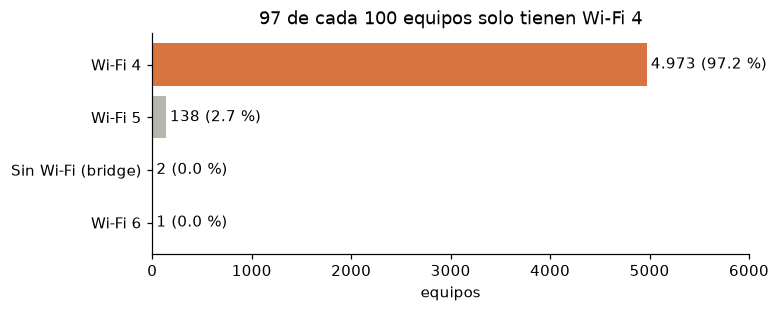

In [6]:
# Distribución de la tecnología Wi-Fi. Wi-Fi 4 trabaja solo en 2,4 GHz; Wi-Fi 5 y 6 suman la banda de 5 GHz.
wifi = onts["WiFi_Tecnologia"].str.extract(r"^(Wi-Fi \d)")[0].fillna("Sin Wi-Fi (bridge)").value_counts()
tabla = pd.DataFrame({"equipos": wifi, "%": (wifi / len(onts) * 100).round(2)})
display(tabla)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(tabla.index[::-1], tabla["equipos"][::-1], color=[GRIS if i != "Wi-Fi 4" else NARANJA for i in tabla.index[::-1]])
for i, (v, p) in enumerate(zip(tabla["equipos"][::-1], tabla["%"][::-1])):
    ax.text(v + 40, i, f"{v:,} ({p:.1f} %)".replace(",", "."), va="center")
ax.set_title("97 de cada 100 equipos solo tienen Wi-Fi 4"); ax.set_xlabel("equipos"); ax.set_xlim(0, 6000)
plt.show()

### 4.2 Puertos de red: el cable también limita

In [7]:
# Configuración de puertos LAN. FE = Fast Ethernet (100 Mb/s); GE = gigabit (1 Gb/s).
lan = onts["Puertos_LAN"].value_counts()
display(pd.DataFrame({"equipos": lan, "%": (lan / len(onts) * 100).round(2)}))
con_fe = onts["Puertos_LAN"].str.contains("FE")
dos_limites = con_fe & onts["WiFi_Tecnologia"].str.startswith("Wi-Fi 4")
print(f"Equipos con algún puerto de 100 Mb/s: {con_fe.sum()} ({con_fe.mean() * 100:.1f} %)")
print(f"Equipos con los dos límites a la vez (Wi-Fi 4 y puertos de 100 Mb/s): {dos_limites.sum()}")

,equipos,%
Puertos_LAN,,
1 GE + 3 FE,4868,95.19
4 GE,243,4.75
1 GE,2,0.04
2 GE + 2 FE,1,0.02


Equipos con algún puerto de 100 Mb/s: 4869 (95.2 %)
Equipos con los dos límites a la vez (Wi-Fi 4 y puertos de 100 Mb/s): 4869


### 4.3 Localidades: el problema no es de una zona

In [8]:
# % de Wi-Fi 4 por localidad: va de 94,7 % a 100 %, así que no hay una zona que explique el problema.
por_loc = onts.groupby("Localidad").agg(equipos=("ID", "size"),
                                        pct_wifi4=("WiFi_Tecnologia", lambda s: s.str.startswith("Wi-Fi 4").mean() * 100))
display(por_loc.sort_values("equipos", ascending=False).round(1))
print(f"Rango de % Wi-Fi 4 entre localidades: {por_loc['pct_wifi4'].min():.1f} % a {por_loc['pct_wifi4'].max():.1f} %")

,equipos,pct_wifi4
Localidad,,
San Vicente,1391,94.7
Frontera,901,97.7
Santa Clara de Buena Vista,856,99.5
Bernardo de Irigoyen,703,98.0
Sastre,463,94.8
Lopez,293,99.7
San Martin de las Escobas,258,98.8
Castelar / Crispi,143,100.0
Larrechea,106,100.0


Rango de % Wi-Fi 4 entre localidades: 94.7 % a 100.0 %


### 4.4 Modelos: tres modelos concentran el 70 % del parque

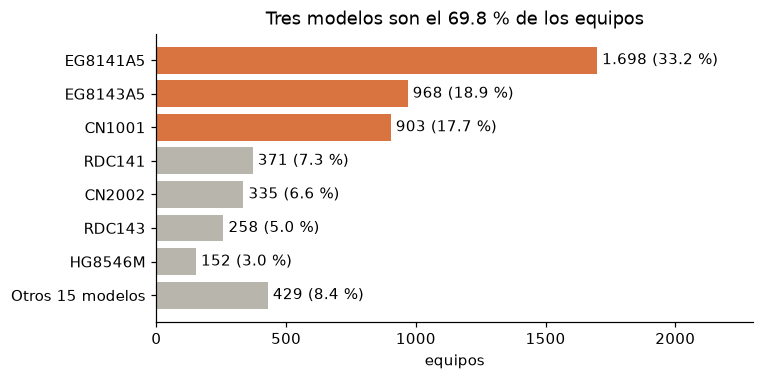

Tecnología Wi-Fi de los tres principales: {'EG8141A5': 'Wi-Fi 4 (2.4 GHz)', 'EG8143A5': 'Wi-Fi 4 (2.4 GHz)', 'CN1001': 'Wi-Fi 4 (2.4 GHz)'}


In [9]:
# Ranking de modelos (nombre canónico). Barras ordenadas, eje desde cero y valores rotulados.
modelos = onts["Modelo_canonico"].value_counts()
top, resto = modelos.head(7), modelos.iloc[7:]
serie = pd.concat([top, pd.Series({f"Otros {len(resto)} modelos": resto.sum()})])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(serie.index[::-1], serie.values[::-1], color=[NARANJA if i >= len(serie) - 3 else GRIS for i in range(len(serie))])
for i, v in enumerate(serie.values[::-1]):
    ax.text(v + 20, i, f"{v:,} ({v / len(onts) * 100:.1f} %)".replace(",", "."), va="center")
ax.set_title(f"Tres modelos son el {modelos.head(3).sum() / len(onts) * 100:.1f} % de los equipos")
ax.set_xlabel("equipos"); ax.set_xlim(0, 2300)
plt.show()
wifi4_modelo = onts.groupby("Modelo_canonico")["WiFi_Tecnologia"].first().loc[modelos.head(3).index]
print("Tecnología Wi-Fi de los tres principales:", wifi4_modelo.to_dict())

### 4.5 Firmware fuera de estándar

Definimos el **firmware estándar** de cada modelo como su versión más común. «Fuera de estándar» no siempre quiere decir
«desactualizado»: algunos equipos tienen una versión más nueva que la mayoritaria, así que la definición hay que validarla
con la empresa. Este hallazgo es el que motiva el TP2.

Fuera de estándar: 1476 de 5114 (28.9 %)


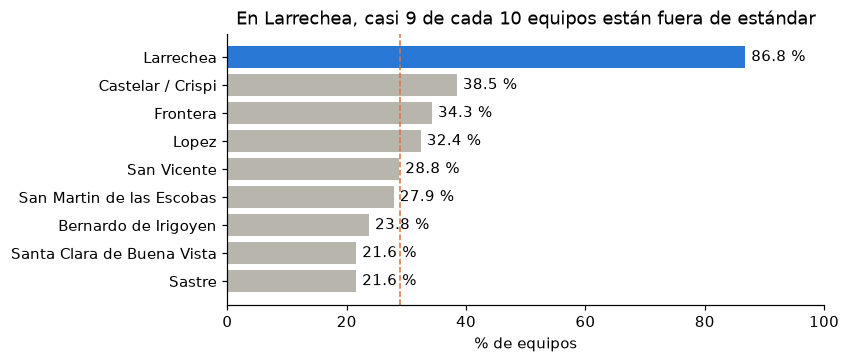

De los fuera de estándar, 578 tienen una generación de firmware MÁS NUEVA que la moda.


In [10]:
# % de equipos con firmware fuera de estándar, total y por localidad.
print(f"Fuera de estándar: {onts['fw_fuera_estandar'].sum()} de {len(onts)} ({onts['fw_fuera_estandar'].mean() * 100:.1f} %)")
fuera_loc = onts.groupby("Localidad")["fw_fuera_estandar"].mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(fuera_loc.index, fuera_loc.values, color=[AZUL if v == fuera_loc.max() else GRIS for v in fuera_loc.values])
ax.axvline(onts["fw_fuera_estandar"].mean() * 100, color=NARANJA, ls="--", lw=1)
for i, v in enumerate(fuera_loc.values):
    ax.text(v + 1, i, f"{v:.1f} %", va="center")
ax.set_title("En Larrechea, casi 9 de cada 10 equipos están fuera de estándar"); ax.set_xlabel("% de equipos")
ax.set_xlim(0, 100)
plt.show()
mas_nuevo = (onts["fw_fuera_estandar"] == 1) & (onts["fw_generacion"] > onts["fw_estandar"].str.extract(r"^V(\d+)")[0].astype(int))
print(f"De los fuera de estándar, {mas_nuevo.sum()} tienen una generación de firmware MÁS NUEVA que la moda.")

### 4.6 Ocupación de las tarjetas

In [11]:
# Equipos por tarjeta: las que quedan debajo del percentil 25 (el 25 % menos ocupado).
por_card = onts.groupby("card_key").agg(onts=("ID", "size"), pon_usados=("pon_key", "nunique")).sort_values("onts")
p25 = por_card["onts"].quantile(0.25)
print(f"Percentil 25 de equipos por tarjeta: {p25}")
display(por_card[por_card["onts"] < p25])

Percentil 25 de equipos por tarjeta: 120.5


,onts,pon_usados
card_key,,
San Martin de las Escobas|2/,4,2
Sastre|3/,34,2
Sastre|2/,105,16
Larrechea|0/,106,11
San Vicente|4/,109,14
San Martin de las Escobas|0/,119,16


## 5. Relación entre variables: ¿la localidad explica el modelo y el Wi-Fi?

Usamos el **V de Cramér**, que mide la asociación entre dos variables categóricas (0 = ninguna, 1 = total). Para el mapa
de calor agrupamos los modelos en los tres principales más «Otros», que es la forma en que se lee el gráfico.

V de Cramér localidad × modelo (3 + Otros): 0.32
V de Cramér localidad × modelo (los 22):    0.27
V de Cramér localidad × Wi-Fi 4:            0.12


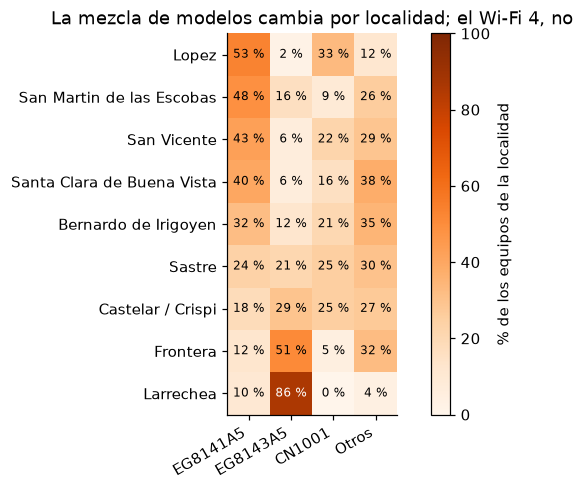

In [12]:
def v_cramer(a, b):
    tabla = pd.crosstab(a, b)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    return np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))

tres = modelos.head(3).index
modelo_agrupado = onts["Modelo_canonico"].where(onts["Modelo_canonico"].isin(tres), "Otros")
wifi4 = onts["WiFi_Tecnologia"].str.startswith("Wi-Fi 4")
print(f"V de Cramér localidad × modelo (3 + Otros): {v_cramer(onts['Localidad'], modelo_agrupado):.2f}")
print(f"V de Cramér localidad × modelo (los 22):    {v_cramer(onts['Localidad'], onts['Modelo_canonico']):.2f}")
print(f"V de Cramér localidad × Wi-Fi 4:            {v_cramer(onts['Localidad'], wifi4):.2f}")

mapa = pd.crosstab(onts["Localidad"], modelo_agrupado, normalize="index")[list(tres) + ["Otros"]] * 100
mapa = mapa.sort_values(tres[0], ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(mapa.values, cmap="Oranges", vmin=0, vmax=100)
ax.set_xticks(range(mapa.shape[1]), mapa.columns, rotation=30, ha="right"); ax.set_yticks(range(mapa.shape[0]), mapa.index)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        ax.text(j, i, f"{mapa.values[i, j]:.0f} %", ha="center", va="center",
                color="white" if mapa.values[i, j] > 60 else "black", fontsize=8)
ax.set_title("La mezcla de modelos cambia por localidad; el Wi-Fi 4, no")
plt.colorbar(im, ax=ax, label="% de los equipos de la localidad")
plt.show()

## 6. Valores atípicos: equipos por puerto PON

Buscamos puertos con una carga fuera de lo común con el criterio del rango intercuartil (IQR): es atípico lo que supera
Q3 + 1,5 × IQR. **Decisión: retenerlos.** Son puertos reales con mucha carga, no errores de carga; recortarlos borraría
equipos que existen.

Q1 = 8, Q3 = 24, límite = 48 equipos por puerto
5 de 301 puertos superan el límite; suman 277 equipos


,equipos
pon_key,
Santa Clara de Buena Vista|1/|14/,73
Santa Clara de Buena Vista|1/|15/,53
Bernardo de Irigoyen|0/|8/,52
San Vicente|2/|12/,50
Bernardo de Irigoyen|0/|2/,49


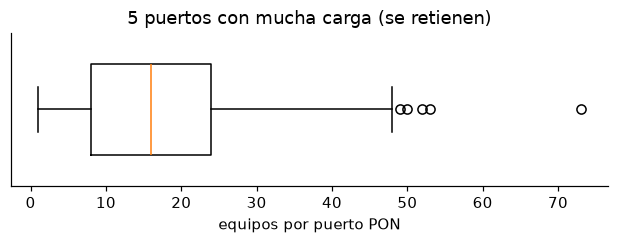

In [13]:
eq_pon = onts.groupby("pon_key").size()
q1, q3 = eq_pon.quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
atipicos = eq_pon[eq_pon > limite].sort_values(ascending=False)
print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, límite = {limite:.0f} equipos por puerto")
print(f"{len(atipicos)} de {len(eq_pon)} puertos superan el límite; suman {atipicos.sum()} equipos")
display(atipicos.to_frame("equipos"))
fig, ax = plt.subplots(figsize=(7, 1.8))
ax.boxplot(eq_pon, orientation="horizontal", widths=0.6)
ax.set_xlabel("equipos por puerto PON"); ax.set_yticks([]); ax.set_title("5 puertos con mucha carga (se retienen)")
plt.show()

## 7. Fuga de datos

Los atributos de hardware (puertos LAN, Wi-Fi, módulo óptico, puertos telefónicos y salida de TV) son una **función
determinística del modelo**. Un modelo de aprendizaje que use uno de ellos para predecir otro «acierta» sin aprender nada,
porque la columna ya trae la respuesta. Lo comprobamos: cada modelo tiene un único valor de cada atributo.

In [14]:
atributos = ["Puertos_LAN", "WiFi_Tecnologia", "Modulo_Optico", "Puertos_POTS", "CATV"]
valores_por_modelo = onts.groupby("Modelo_canonico")[atributos].nunique()
print("Máximo de valores distintos de cada atributo dentro de un mismo modelo:")
display(valores_por_modelo.max().to_frame("valores distintos (máx.)"))
catv = onts["CATV"].eq("Sí")
print(f"Equipos con salida de TV: {catv.sum()}; todos pertenecen a los modelos {sorted(onts.loc[catv, 'Modelo_canonico'].unique())}")
print("Conclusión: en los TP2 y TP3 ninguna de estas columnas se usa para predecir el modelo ni al revés.")

Máximo de valores distintos de cada atributo dentro de un mismo modelo:


,valores distintos (máx.)
Puertos_LAN,1
WiFi_Tecnologia,1
Modulo_Optico,1
Puertos_POTS,1
CATV,1


Equipos con salida de TV: 1025; todos pertenecen a los modelos ['EG8143A5', 'EG8247W5', 'HG8247H5']
Conclusión: en los TP2 y TP3 ninguna de estas columnas se usa para predecir el modelo ni al revés.


## 8. Indicador, meta SMART y plan de recambio

**Indicador:** % de ONT con Wi-Fi 5 o superior = (Wi-Fi 5 + Wi-Fi 6) / total del inventario.

**Meta SMART:** pasar del valor actual al que resulta de reemplazar el modelo más común (EG8141A5) por equipos con Wi-Fi 5
o superior, como etapa 1, al 31/12/2027. Es específica (un modelo), medible (el indicador), alcanzable (con los datos
del inventario, sin fuentes externas), relevante (el equipo fija el techo del servicio) y temporal (fecha fija).

In [15]:
moderno_wifi = onts["WiFi_Tecnologia"].str.contains(r"Wi-Fi [56]")
eg = onts["Modelo_canonico"] == "EG8141A5"
hoy = moderno_wifi.mean() * 100
meta = (moderno_wifi.sum() + eg.sum()) / len(onts) * 100
print(f"Indicador hoy: {hoy:.1f} % ({moderno_wifi.sum()} de {len(onts)} equipos)")
print(f"Meta etapa 1 (reemplazar los {eg.sum()} EG8141A5): {meta:.1f} % al 31/12/2027")
print(f"Piloto propuesto: los {int((eg & (onts['Localidad'] == 'San Vicente')).sum())} EG8141A5 de San Vicente")
plan = pd.DataFrame([("30/11/2026", "Definir el equipo de reemplazo (con TV por cable para el EG8143A5)"),
                     ("01/12/2026", "Altas nuevas: solo Wi-Fi 5 o superior"),
                     ("31/03/2027", "Piloto con los EG8141A5 de San Vicente"),
                     ("31/12/2027", f"Etapa 1 completa: {eg.sum()} equipos → {meta:.1f} %")], columns=["fecha", "hito"])
display(plan)

Indicador hoy: 2.7 % (139 de 5114 equipos)
Meta etapa 1 (reemplazar los 1698 EG8141A5): 35.9 % al 31/12/2027
Piloto propuesto: los 593 EG8141A5 de San Vicente


,fecha,hito
0,30/11/2026,Definir el equipo de reemplazo (con TV por cab...
1,01/12/2026,Altas nuevas: solo Wi-Fi 5 o superior
2,31/03/2027,Piloto con los EG8141A5 de San Vicente
3,31/12/2027,Etapa 1 completa: 1698 equipos → 35.9 %


## 9. Conclusiones

1. **El límite no está en la fibra, está en el módem del cliente.** El 97 % de las ONT solo tiene Wi-Fi 4 y el 95 % tiene
   puertos de 100 Mb/s.
2. **No es un problema de zona.** El Wi-Fi 4 va de 94,7 % a 100 % en todas las localidades (V de Cramér 0,12); lo que
   cambia por localidad es la mezcla de modelos, y tres modelos concentran el 70 % del parque.
3. **El recambio debe planificarse por modelo**, empezando por el EG8141A5: llevaría el indicador de 2,7 % a 35,9 %.
4. **Lo que queda para los siguientes trabajos:** el 28,9 % de los equipos tiene el firmware fuera de estándar (TP2) y los
   atributos de hardware dependen del modelo, una fuga de datos que hay que evitar al predecir (TP3).